# Figure

Semi-synthetic analysis of `Experiments/semi_synthetic/outputs/bert_pca_75_horizon_3`.

**What the experiment does.** Starting from the real Geneva dispatch-centre target
(`dataset_matching_horizon_3.pkl`: 1,071 days, horizon = 3 days), the pipeline deletes the
informative tweets the classifier actually found in the corpus and *injects* synthetic
informative tweets at a controlled daily rate $\lambda_0$, drawn with replacement from the
518-tweet informative pool. A BERT-PCA XGBoost model is then retrained per
($\lambda_0$, seed, fold), so AUROC becomes a function of a single knob: how many
informative tweets per day exist.

**The question the main figure answers.** How many informative tweets per day are needed
before the tweet channel carries predictive signal at all — and how does that compare with
the density the real corpus actually produces?

This notebook is **read-only** with respect to the experiment: it consumes the run artifacts
and writes figures/tables into `Figures/outputs/`. The cell below is the only place to edit to
point at another run.

In [ ]:
from __future__ import annotations

import json


import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedFormatter, FixedLocator
from sklearn.metrics import roc_auc_score

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)


def find_repo_root(start: Path) -> Path:
    """Walk upwards until the semi-synthetic experiment directory is visible."""
    for candidate in [start, *start.parents]:
        if (candidate / "Experiments" / "semi_synthetic" / "outputs").is_dir():
            return candidate
    raise FileNotFoundError(f"No Experiments/semi_synthetic/outputs below {start}")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
EXPERIMENT = "bert_pca_75_horizon_3"
EXPERIMENT_DIR = REPO_ROOT / "Experiments" / "semi_synthetic" / "outputs" / EXPERIMENT
OUTPUT_DIR = REPO_ROOT / "Figures" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"repo     {REPO_ROOT}")
print(f"run      {EXPERIMENT_DIR}")
print(f"outputs  {OUTPUT_DIR}")

repo     /home/felicien/code/tweets_ems_calls
run      /home/felicien/code/tweets_ems_calls/Experiments/semi_synthetic/outputs/bert_pca_75_horizon_3
outputs  /home/felicien/code/tweets_ems_calls/Figures/outputs


## 1. Load the run artifacts

`results.csv` holds one row per (model, $\lambda_0$, seed, fold); `predictions.csv` holds the
per-day test predictions behind those AUROCs; `config.json` records the run design.

In [3]:
config = json.loads((EXPERIMENT_DIR / "config.json").read_text(encoding="utf-8"))
pool_report = json.loads((EXPERIMENT_DIR / "pool_report.json").read_text(encoding="utf-8"))
results = pd.read_csv(EXPERIMENT_DIR / "results.csv")
predictions = pd.read_csv(EXPERIMENT_DIR / "predictions.csv")

bert_cfg = config.get("bert_pca", {})
print(f"experiment        {config['experiment']}   dataset {config['dataset_name']}")
print(f"method            {config['method']}   pool {config['pool']}   "
      f"keep_real_informative={config['keep_real_informative']}")
print(f"lambda0           {config['lambdas']}")
print(f"seeds             {config['seeds']}   optuna trials {config['num_trials']}")
print(f"feature window    {config['feature_window']} days (lags {config['feature_lags']})"
      f" -> {results['n_features'].max()} input features")
print(f"BERT PCA          k={bert_cfg.get('n_components')} at {bert_cfg.get('variance_threshold')} "
      f"explained variance, fitted on {bert_cfg.get('n_tweets')} tweets "
      f"({bert_cfg.get('fit_population')})")
print(f"informative pool  {pool_report['n_unique']} tweets, "
      f"{pool_report['first_day']} .. {pool_report['last_day']}")
print(f"baseline trained  with_baseline={config['with_baseline']} "
      f"-> {len(results[results.model == 'baseline'])} baseline rows")


experiment        bert_pca_75_horizon_3   dataset dataset_matching_horizon_3.pkl
method            bert   pool informative   keep_real_informative=False
lambda0           [0, 0.1, 0.5, 1, 2.5, 5, 10, 20, 50]
seeds             [0, 1, 2]   optuna trials 100
feature window    3 days (lags [1, 2]) -> 57 input features
BERT PCA          k=19 at 0.75 explained variance, fitted on 41714 tweets (full_bert_cache)
informative pool  518 tweets, 2020-02-17 .. 2022-12-28
baseline trained  with_baseline=False -> 0 baseline rows


In [5]:
N_TEST_DAYS = int(predictions.groupby(["seed", "fold"])["date"].nunique().median())
# n_injected_total counts injected tweets over the WHOLE reference table, while predictions.csv
# only holds the per-fold test window. Dividing one by the other understates the realised rate
# by the train/test ratio, so the reference length comes from the dataset the run was built on.
N_REFERENCE_DAYS = len(pd.read_pickle(config["reference_pkl"]))
MODELS = sorted(results["model"].unique())
LAMBDAS = sorted(results["lambda0"].unique())
SEEDS = sorted(results["seed"].unique())
FOLDS = sorted(results["fold"].unique())

# Real-world informative-tweet densities measured on the full corpus
# (signal_density/outputs_full, prompt relevance_v3, 41,714 unique tweets over the same
# 1,071 reference days). They mark the part of the x-axis the real data actually occupies.
REAL_DENSITIES = {
    "v3 hard (p>=0.5)": 0.48,
    "v3 p>=0.05": 2.49,
    "v2 hard (p>=0.5)": 4.89,
}
REAL_LO, REAL_HI = min(REAL_DENSITIES.values()), max(REAL_DENSITIES.values())

assert results["auroc"].notna().all(), "results.csv has NaN AUROC"
print(f"{len(results)} rows | models={MODELS} | {len(LAMBDAS)} lambdas x {len(SEEDS)} seeds "
      f"x {len(FOLDS)} folds")
print(f"reference table: {N_REFERENCE_DAYS} days | test window per fold: {N_TEST_DAYS} days")
print(f"positives per fold: {results.n_pos_test.min()}-{results.n_pos_test.max()}")

81 rows | models=['bert'] | 9 lambdas x 3 seeds x 3 folds
reference table: 1071 days | test window per fold: 160 days
positives per fold: 39-54


In [8]:
from auroc_vs_lambda import summarise, baseline_auroc, optimal_auroc

per_seed, summary = summarise(results, "auroc")
base = baseline_auroc(results)

table = summary.assign(
    gain=summary["mean"],
    bound=optimal_auroc(summary["lambda0"].to_numpy(), delta=0.2, window=7, method="normal"),
)[["model", "pool", "lambda0", "mean", "lo", "hi", "gain", "bound", "n_seeds"]]
table = table.rename(columns={"mean": "auroc", "lo": "min_seed", "hi": "max_seed"})


table.round(3)

,model,pool,lambda0,auroc,min_seed,max_seed,gain,bound,n_seeds
0,bert,informative,0.0,0.498,0.498,0.498,0.498,0.500,3
1,bert,informative,0.1,0.524,0.508,0.537,0.524,0.545,3
2,bert,informative,0.5,0.524,0.500,0.542,0.524,0.600,3
3,bert,informative,1.0,0.516,0.501,0.531,0.516,0.639,3
4,bert,informative,2.5,0.551,0.521,0.571,0.551,0.714,3
5,bert,informative,5.0,0.607,0.577,0.647,0.607,0.787,3
6,bert,informative,10.0,0.639,0.620,0.666,0.639,0.870,3
7,bert,informative,20.0,0.684,0.679,0.688,0.684,0.945,3
8,bert,informative,50.0,0.717,0.681,0.736,0.717,0.994,3


Saved /home/felicien/code/tweets_ems_calls/Figures/outputs/fig_auroc_lexicon.pdf and .png
Saved /home/felicien/code/tweets_ems_calls/Figures/outputs/fig_auroc_bert.pdf and .png
Saved /home/felicien/code/tweets_ems_calls/Figures/outputs/fig_auroc_both.pdf and .png


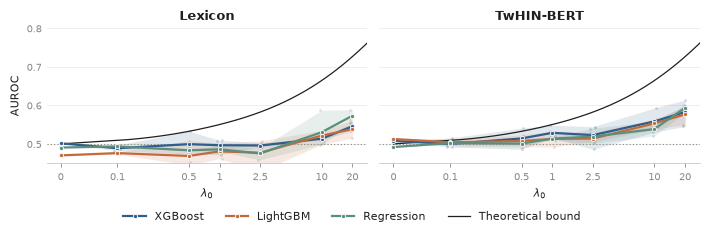

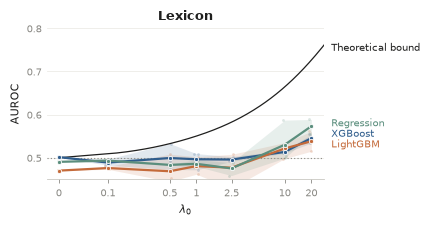

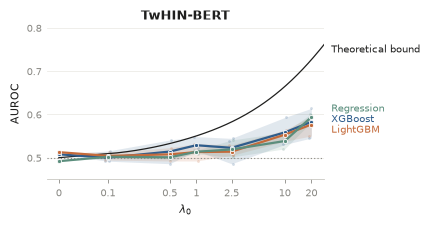

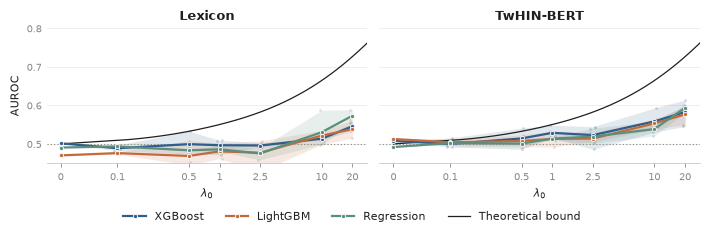

In [1]:
from auroc_vs_lambda import load_experiment, plot_models_vs_lambda, plot_side_by_side
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    """Walk upwards until the semi-synthetic experiment directory is visible."""
    for candidate in [start, *start.parents]:
        if (candidate / "Experiments" / "semi_synthetic" / "outputs").is_dir():
            return candidate
    raise FileNotFoundError(f"No Experiments/semi_synthetic/outputs below {start}")


REPO_ROOT = find_repo_root(Path.cwd().resolve())

OUTPUTS = REPO_ROOT / "Experiments" / "semi_synthetic" / "outputs"

OUTPUT_DIR = REPO_ROOT / "Figures" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

lexicon = load_experiment(OUTPUTS, "lexicon")
bert = load_experiment(OUTPUTS, "bert")

# one figure per experiment
plot_models_vs_lambda(lexicon, OUTPUT_DIR / "fig_auroc_lexicon", title="Lexicon")
plot_models_vs_lambda(bert, OUTPUT_DIR / "fig_auroc_bert", title="TwHIN-BERT")
plot_side_by_side({"Lexicon": lexicon, "TwHIN-BERT": bert}, OUTPUT_DIR / "fig_auroc_both")

In [2]:
from auroc_vs_lambda import load_experiment, auroc_table

lexicon = load_experiment(OUTPUTS, "lexicon", max_lambda=20)
bert = load_experiment(OUTPUTS, "bert", max_lambda=20)

table = auroc_table({"Lexicon": lexicon, "TwHIN-BERT": bert})


=== Lexicon: mean test AUROC (folds, then seeds) [seed min-max] ===
model                XGBoost             LightGBM           Regression  Bound
lambda0                                                                      
0.0      0.501 [0.501-0.501]  0.470 [0.470-0.470]  0.491 [0.491-0.491]  0.500
0.1      0.489 [0.483-0.497]  0.476 [0.473-0.480]  0.493 [0.491-0.495]  0.509
0.5      0.499 [0.473-0.533]  0.469 [0.445-0.508]  0.483 [0.483-0.485]  0.533
1.0      0.497 [0.472-0.510]  0.481 [0.462-0.502]  0.486 [0.480-0.496]  0.550
2.5      0.496 [0.492-0.503]  0.477 [0.429-0.508]  0.475 [0.459-0.489]  0.583
10.0     0.514 [0.511-0.517]  0.522 [0.498-0.535]  0.530 [0.499-0.587]  0.664
20.0     0.546 [0.534-0.554]  0.538 [0.515-0.561]  0.573 [0.554-0.589]  0.726

=== TwHIN-BERT: mean test AUROC (folds, then seeds) [seed min-max] ===
model                XGBoost             LightGBM           Regression  Bound
lambda0                                                                      
0